Add CSU Salary Schedule Information to the Model dataset
https://www.calstate.edu/csu-system/careers/compensation/Pages/salary-schedule.aspx 

In [ ]:
import pandas as pd

salary_schedule_df = pd.read_csv('../Data/SalaryRecs.csv')
csu_data_df = pd.read_parquet('../Data/model_csu_depbucket_cleaned_joined_pay_2013-2024.parquet')

csu_data_df = csu_data_df.loc[
    pd.to_numeric(csu_data_df["year_transparentCA"], errors="coerce").eq(2024)
].copy().reset_index(drop=True)

salary_schedule_df["Effective Date"] = pd.to_datetime(
    salary_schedule_df["Effective Date"], format="%m/%d/%Y", errors="coerce"
)
salary_schedule_df = salary_schedule_df.loc[
    salary_schedule_df["Effective Date"].le(pd.Timestamp("2024-12-31"))
].copy().reset_index(drop=True)


In [ ]:
salary_schedule_df.head()


,Class,Range,Effective Date,Class Title,Min Salary,Max Salary,CBID,Status,Status Code,Pay Letter,...,Step 23,Step 24,Step 25,Step 26,Step 27,Step 28,Step 29,Step 30,Step 31,Step 32
0,605,1,2024-07-01,VETERINARIAN I,"$5,354.00","$9,417.00",R01,Active,1,2407,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,605,6,2024-07-01,VETERINARIAN I,"$4,908.00","$8,632.00",R01,Active,1,2407,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,605,8,2024-07-01,VETERINARIAN I,"$4,462.00","$7,848.00",R01,Active,1,2407,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,608,1,2024-07-01,VETERINARIAN II,"$6,451.00","$11,366.00",R01,Active,1,2407,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,608,6,2024-07-01,VETERINARIAN II,"$5,913.00","$10,419.00",R01,Active,1,2407,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
csu_data_df.head()

,year_transparentCA,school,name,title,job,original_department,department,total_pay,base_pay,overtime_pay,other_pay
0,2024,CSU Bakersfield,Abigael Flachmann,Lecturer in English,lecturer - academic year,English,Humanities & Languages,87898,78450,0,9448
1,2024,CSU Bakersfield,Abolfazl Kiani,Lecturer in Chemistry and Biochemistry,lecturer - academic year,Chemistry and Biochemistry,Science & Mathematics,91781,84237,0,7544
2,2024,CSU Bakersfield,Adam Sawyer,Professor,instructional faculty - academic year,Teacher Education,Education & Public Administration,121679,100557,0,21122
3,2024,CSU Bakersfield,Adam Schuster,Professor,instructional faculty - academic year,English,Humanities & Languages,76313,76113,0,200
4,2024,CSU Bakersfield,Adelmira Ynostroza Ochoa,Professor,instructional faculty - academic year,Teacher Education,Education & Public Administration,96142,82847,0,13294


In [ ]:
salary_schedule_df["Effective Date"].unique()

<DatetimeArray>
['2024-07-01 00:00:00', '2018-07-01 00:00:00', '2020-01-01 00:00:00',
 '2022-07-01 00:00:00', '2019-01-01 00:00:00', '2023-10-01 00:00:00',
 '2023-11-01 00:00:00', '2017-11-01 00:00:00', '2024-10-01 00:00:00',
 '2024-06-01 00:00:00']
Length: 10, dtype: datetime64[us]

In [ ]:
salary_schedule_df["Class Title"].unique()

<ArrowStringArray>
[                                         'VETERINARIAN I',
                                         'VETERINARIAN II',
                                   'NURSERY TECHNICIAN II',
                                    'NURSERY TECHNICIAN I',
                                       'PRESIDENTIAL AIDE',
                         'INSTRUCTIONAL STUDENT ASSISTANT',
  'INSTRUCTIONAL STUDENT ASSISTANT - ON CAMPUS WORK STUDY',
            'INSTRUCTIONAL STUDENT ASSISTANT - OFF CAMPUS',
 'INSTRUCTIONAL STUDENT ASSISTANT - OFF CAMPUS WORK STUDY',
                'CONFIDENTIAL TECHNICAL SUPPORT -12 MONTH',
 ...
   'STUDENT SERVICES PROFESSIONAL IV - ACADEMIC YEAR - NE',
        'STUDENT SERVICES PROFESSIONAL IV - 10 MONTH - NE',
                                'CORE ELP INSTRUCTOR - NE',
                     'PHYSICIAN - SPECIALTY SERVICES - NE',
                    'ALLIED HEALTH SVCS PROVIDER (A) - NE',
                    'ALLIED HEALTH SVCS PROVIDER (B) - NE',
                

In [ ]:
# Broad search for potentially teaching-related job titles.
# INSTRUCTR handles an abbreviation present in your data.
pattern = (
    r"\b(?:INSTRUCTOR|INSTRUCTIONAL | INSTRUCTR|PROFESSOR|LECTURER)S?\b"
    r"|\bFACULTY\b"
    r"|\bTEACH(?:ER|ERS|ING)?\b"
    r"|\bDEPARTMENT CHAIR\b"
)

titles = salary_schedule_df["Class Title"].astype("string").str.strip()

possible_teaching_titles = (
    titles[
        titles.str.contains(pattern, case=False, na=False)
        & ~titles.str.contains(r"\bDEDUCTION\b", case=False, na=False)
    ]
    .dropna()
    .drop_duplicates()
    .sort_values()
    .tolist()
)

print(f"Found {len(possible_teaching_titles)} possible teaching-related titles:\n")
print("\n".join(possible_teaching_titles))

Found 61 possible teaching-related titles:

CORE ELP INSTRUCTOR
CORE ELP INSTRUCTOR - NE
DEMONSTRATION INSTRUCTIONAL FACULTY
DEMONSTRATION INSTRUCTIONAL FACULTY - ACA
DEPARTMENT CHAIR - 12 MONTH
DEPARTMENT CHAIR - ACADEMIC YEAR
DEPARTMENT CHAIR, STATEWIDE NURSING PROGRAM -ACADEMIC YEAR
DEPARTMENT CHAIR, SUMMER TERM
ENGLISH LANGUAGE PROGRAM SUBSTITUTE INSTRUCTOR
FT FACULTY UNIT - ADDITIONAL EMPLOYMENT
GRANT-RELATED/SPECIALLY FUNDED INSTRUCTIONAL FACULTY - 12MO
GRANT-RELATED/SPECIALLY FUNDED INSTRUCTIONAL FACULTY - AY
INSTRUCTIONAL FACULTY - 12 MONTH
INSTRUCTIONAL FACULTY - ACADEMIC YEAR
INSTRUCTIONAL FACULTY - ACADEMIC YEAR *
INSTRUCTIONAL FACULTY - SUMMER ARTS PROGRAM
INSTRUCTIONAL FACULTY - SUMMER ARTS PROGRAM - ACA
INSTRUCTIONAL FACULTY, CHAIRMAN, ACADEMIC SENATE
INSTRUCTIONAL FACULTY, DIRECTOR, INSTITUTE FOR TCHNG/LEARNING
INSTRUCTIONAL FACULTY, EXECUTIVE COMMITTEE, ACADEMIC SENATE
INSTRUCTIONAL FACULTY, EXT. FOR CREDIT - ACA - G RATE
INSTRUCTIONAL FACULTY, EXTENSION -FOR CREDIT
INS

In [ ]:
def normalize_job(series):
    return (
        series.astype("string")
        .str.strip()
        .str.casefold()
        .str.replace(r"\s+", " ", regex=True)
        .str.replace(r"\s*-\s*", "-", regex=True)
        .replace("", pd.NA)
    )

csu = csu_data_df.assign(
    _job_key=normalize_job(csu_data_df["job"])
)

schedule = salary_schedule_df.assign(
    _job_key=normalize_job(salary_schedule_df["Class Title"])
).dropna(subset=["_job_key"])

csu_salary_joined_df = csu.merge(
    schedule,
    on="_job_key",
    how="left",
    suffixes=("", "_schedule"),
    indicator="salary_match",
).drop(columns="_job_key")

# Review jobs that did not match the salary schedule.
unmatched_jobs = (
    csu_salary_joined_df.loc[
        csu_salary_joined_df["salary_match"].eq("left_only"), "job"
    ]
    .drop_duplicates()
    .sort_values()
)

print(f"Rows before: {len(csu_data_df):,}")
print(f"Rows after:  {len(csu_salary_joined_df):,}")
print(f"Unmatched job titles: {len(unmatched_jobs):,}")

display(csu_salary_joined_df.head())

Rows before: 11,060
Rows after:  43,960
Unmatched job titles: 0


,year_transparentCA,school,name,title,job,original_department,department,total_pay,base_pay,overtime_pay,...,Step 24,Step 25,Step 26,Step 27,Step 28,Step 29,Step 30,Step 31,Step 32,salary_match
0,2024,CSU Bakersfield,Abigael Flachmann,Lecturer in English,lecturer - academic year,English,Humanities & Languages,87898,78450,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,both
1,2024,CSU Bakersfield,Abigael Flachmann,Lecturer in English,lecturer - academic year,English,Humanities & Languages,87898,78450,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,both
2,2024,CSU Bakersfield,Abigael Flachmann,Lecturer in English,lecturer - academic year,English,Humanities & Languages,87898,78450,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,both
3,2024,CSU Bakersfield,Abigael Flachmann,Lecturer in English,lecturer - academic year,English,Humanities & Languages,87898,78450,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,both
4,2024,CSU Bakersfield,Abolfazl Kiani,Lecturer in Chemistry and Biochemistry,lecturer - academic year,Chemistry and Biochemistry,Science & Mathematics,91781,84237,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,both


In [ ]:
csu_salary_joined_df["Range Title"].unique()

<ArrowStringArray>
[                  'A',                   'B',                   'C',
                   'D',          'INSTRUCTOR', 'ASSISTANT PROFESSOR',
 'ASSOCIATE PROFESSOR',           'PROFESSOR',                   nan,
           'ASSISTANT',       'SEMESTER RATE',        'QUARTER RATE']
Length: 12, dtype: str

In [ ]:
import re
import pandas as pd

def clean_title(value):
    if pd.isna(value):
        return ""
    # Handle scraped text such as "CoordinatorAssociate Professor".
    value = re.sub(r"(?<=[a-z])(?=[A-Z])", " ", str(value))
    return re.sub(r"[^a-z0-9]+", " ", value.casefold()).strip()


# Keep assistant and associate professor separate.
rank_pattern = re.compile(
    r"\b(?:(assistant|asst|assis|associate|associat|assoc|assc)\s+"
    r"(?:(?:clinical|research|visiting|adjunct)\s+)*)?"
    r"(professor|prof)\b"
    r"|\b(lecturer|lecturtrer|instructor)(?:\s+(iii|ii|iv|i|[a-d]))?\b"
)


def title_rank(value):
    text = clean_title(value)

    # Some title values contain scraped biographies; leave these for review.
    if len(text) > 350:
        return pd.NA

    ranks = set()

    for match in rank_pattern.finditer(text):
        qualifier, professor, role, level = match.groups()

        if professor:
            if qualifier in {"assistant", "asst", "assis"}:
                rank = "assistant professor"
            elif qualifier:
                rank = "associate professor"
            else:
                rank = "professor"
        else:
            role = "lecturer" if role == "lecturtrer" else role
            rank = role + (f" {level}" if level else "")

        ranks.add(rank)

    # Defaults for titles without an explicit rank.
    # Preserve ranks such as Associate Professor even when also a chair.
    if not ranks and re.search(r"\b(?:emerit(?:us|a|i|u)?|chair(?:person|man|woman)?)\b", text):
        return "professor"

    if not ranks and text == "instructional faculty":
        return "instructor"

    # Other missing or conflicting ranks remain unresolved.
    return next(iter(ranks)) if len(ranks) == 1 else pd.NA


def job_key(series):
    return (
        series.astype("string")
        .str.strip()
        .str.casefold()
        .str.replace(r"\s+", " ", regex=True)
        .str.replace(r"\s*-\s*", "-", regex=True)
        .replace("", pd.NA)
    )


# Title overrides; otherwise match within the payroll job.
from functools import lru_cache

schedule = salary_schedule_df.copy().reset_index(drop=True)
schedule["_salary_row_id"] = pd.array(range(len(schedule)), dtype="Int64")
schedule["_job_key"] = job_key(schedule["Class Title"])
schedule["_range_key"] = schedule["Range Title"].map(clean_title)
schedule_groups = {
    key: group for key, group in schedule.dropna(subset=["_job_key"]).groupby("_job_key")
}

# Explicit combined rank labels in the substitute-faculty classification.
combined_ranges = {
    "a asst instructor": {"instructor"},
    "b asst professor": {"assistant professor"},
    "c assoc prof prof": {"associate professor", "professor"},
}


@lru_cache(maxsize=None)
def choose_salary_range(job, extracted_rank, title_rule=None):
    candidates = schedule_groups.get(job)
    override_method = None
    if isinstance(title_rule, str) and title_rule in {"instructional faculty", "lecturer"}:
        preferred = {"instructor"} if title_rule == "instructional faculty" else {"a", "range a"}
        selected = (candidates.loc[candidates["_range_key"].isin(preferred)]
                    if candidates is not None else pd.DataFrame())
        if not selected.empty:
            candidates = selected
            override_method = "title rule: " + ("Instructor" if title_rule == "instructional faculty" else "Range A")
        else:
            # Preserve 12-month jobs; default other title overrides to academic year.
            twelve_month = bool(re.search(r"12\s*(?:month|mo)\b", job or ""))
            term = "12 month" if twelve_month else "academic year"
            classification = "instructional faculty" if title_rule == "instructional faculty" else "lecturer"
            target = classification + "-" + term
            candidates = schedule_groups.get(target)
            if candidates is not None:
                candidates = candidates.loc[candidates["_range_key"].isin(preferred)]
            override_method = "title override: " + classification + " / " + term
    if candidates is None or candidates.empty:
        return (None, None, "unmatched", "Job classification not found", "")

    labels = candidates["Range Title"].fillna("(blank)").astype(str).str.strip()
    available = " | ".join(labels.drop_duplicates())

    def select(rows, method):
        if len(rows) != 1:
            return (None, None, "unmatched", "Multiple schedule rows fit the rule", available)
        row = rows.iloc[0]
        rank = row["_range_key"] or None
        return (int(row["_salary_row_id"]), rank, method, "", available)

    if override_method is not None:
        return select(candidates, override_method)

    # Blank Range Title is valid when this job has only one schedule row.
    if len(candidates) == 1:
        return select(candidates, "single salary range for job")

    # Lecturer jobs default to A or maritime II.
    if re.search(r"\blecturer\b", job):
        maritime = bool(re.search(r"\b(?:maritime|cma)\b", job))
        preferred = {"lecturer ii"} if maritime else {"a", "range a"}
        selected = candidates.loc[candidates["_range_key"].isin(preferred)]
        if not selected.empty:
            return select(selected, "job default: Lecturer II" if maritime else "job default: Range A")
        return (None, None, "unmatched", "Lecturer default not available for this job", available)

    if extracted_rank is not None:
        compatible = candidates["_range_key"].map(
            lambda label: extracted_rank in combined_ranges.get(label, {label})
        )
        if compatible.any():
            return select(candidates.loc[compatible], "job plus compatible title rank")
        reason = "Title rank unavailable under payroll job; job retained"
    else:
        reason = "Job has multiple ranges; title does not identify a rank"

    return (None, None, "unmatched", reason, available)


csu = csu_data_df.copy()
csu["_job_key"] = job_key(csu["job"])
csu["extracted_rank"] = csu["title"].map(title_rank)
csu["title_rule"] = [
    "instructional faculty" if clean_title(title) == "instructional faculty"
    else "lecturer" if pd.notna(rank) and rank.startswith("lecturer")
    else None
    for title, rank in zip(csu["title"], csu["extracted_rank"])
]
choices = [
    choose_salary_range(None if pd.isna(job) else job,
                        None if pd.isna(rank) else rank,
                        None if pd.isna(rule) else rule)
    for job, rank, rule in zip(csu["_job_key"], csu["extracted_rank"], csu["title_rule"])
]
selection = pd.DataFrame(choices, columns=[
    "_salary_row_id", "matched_rank", "match_method",
    "unmatched_reason", "available_range_titles",
])
selection["_salary_row_id"] = pd.array(selection["_salary_row_id"], dtype="Int64")
for column in selection:
    csu[column] = selection[column].array

csu_salary_joined_df = csu.merge(
    schedule.drop(columns=["_job_key", "_range_key"]),
    on="_salary_row_id",
    how="left",
    validate="many_to_one",
    indicator="salary_match",
    suffixes=("", "_schedule"),
).drop(columns=["_job_key", "_salary_row_id"])

assert len(csu_salary_joined_df) == len(csu_data_df)
assert csu_salary_joined_df["year_transparentCA"].eq(2024).all()
matched_dates = csu_salary_joined_df.loc[
    csu_salary_joined_df["salary_match"].eq("both"), "Effective Date"
]
assert matched_dates.notna().all() and matched_dates.le(pd.Timestamp("2024-12-31")).all()

# Only explicitly identified titles may use a title override.
used_title_rule = csu_salary_joined_df["match_method"].str.startswith(("title rule:", "title override:"))
assert csu_salary_joined_df.loc[used_title_rule, "title_rule"].isin(
    ["instructional faculty", "lecturer"]
).all(), "A record without a title rule received a title override"

# Professor ranks in the main faculty classifications must remain distinct.
faculty_jobs = job_key(csu_salary_joined_df["job"]).isin([
    "instructional faculty-academic year", "instructional faculty-academic year *",
    "instructional faculty-12 month",
])
professor_ranks = csu_salary_joined_df["extracted_rank"].isin([
    "professor", "associate professor", "assistant professor",
])
rank_check = csu_salary_joined_df.loc[faculty_jobs & professor_ranks]
assert rank_check["Range Title"].map(clean_title).eq(rank_check["extracted_rank"]).all(), (
    "A professor rank was incorrectly reassigned"
)

In [ ]:
# Unmatched titles by university.
unmatched_titles = (
    csu_salary_joined_df.loc[
        csu_salary_joined_df["salary_match"].eq("left_only"),
        ["school", "title", "job", "extracted_rank",
         "unmatched_reason", "available_range_titles"],
    ]
    .value_counts(dropna=False)
    .rename("rows")
    .reset_index()
)

unmatched_titles.head(25)

,school,title,job,extracted_rank,unmatched_reason,available_range_titles,rows
0,CSU Los Angeles,NaN,instructional faculty - academic year,NaN,Job has multiple ranges; title does not identi...,INSTRUCTOR | ASSISTANT PROFESSOR | ASSOCIATE P...,254
1,CSU Long Beach,NaN,instructional faculty - academic year,NaN,Job has multiple ranges; title does not identi...,INSTRUCTOR | ASSISTANT PROFESSOR | ASSOCIATE P...,69
2,San Diego State University,Adjunct,instructional faculty - academic year,NaN,Job has multiple ranges; title does not identi...,INSTRUCTOR | ASSISTANT PROFESSOR | ASSOCIATE P...,13
3,CSU Channel Islands,NaN,instructional faculty - academic year,NaN,Job has multiple ranges; title does not identi...,INSTRUCTOR | ASSISTANT PROFESSOR | ASSOCIATE P...,7
4,Sonoma State University,"Instr Fac,Extension Non-Credit",instructional faculty - academic year,NaN,Job has multiple ranges; title does not identi...,INSTRUCTOR | ASSISTANT PROFESSOR | ASSOCIATE P...,5
5,Cal Poly Humboldt,Director,instructional faculty - academic year,NaN,Job has multiple ranges; title does not identi...,INSTRUCTOR | ASSISTANT PROFESSOR | ASSOCIATE P...,3
6,"California State University, Chico",Director,instructional faculty - academic year,NaN,Job has multiple ranges; title does not identi...,INSTRUCTOR | ASSISTANT PROFESSOR | ASSOCIATE P...,2
7,"California State University, Chico",Program Coordinator,instructional faculty - academic year,NaN,Job has multiple ranges; title does not identi...,INSTRUCTOR | ASSISTANT PROFESSOR | ASSOCIATE P...,2
8,Sonoma State University,"Instr Fac,Spcl Pgms-For Credit",instructional faculty - academic year,NaN,Job has multiple ranges; title does not identi...,INSTRUCTOR | ASSISTANT PROFESSOR | ASSOCIATE P...,2
9,CSU Channel Islands,NaN,instructional faculty - 12 month,NaN,Job has multiple ranges; title does not identi...,INSTRUCTOR | ASSISTANT PROFESSOR | ASSOCIATE P...,1


In [ ]:
# Overall summary (counts are records across years).
summary_df = csu_salary_joined_df.copy()
matched = summary_df["salary_match"].eq("both")
total = len(summary_df)

summary_metrics = pd.DataFrame({
    "Metric": [
        "Total records", "Matched records", "Unmatched records", "Match rate (%)",
        "Distinct school/name pairs (approximate people)", "Universities",
        "Records missing original title", "Records using a title classification override",
    ],
    "Value": [
        total, int(matched.sum()), int((~matched).sum()),
        round(100 * matched.mean(), 2) if total else 0,
        len(summary_df[["school", "name"]].drop_duplicates()),
        summary_df["school"].nunique(),
        int(summary_df["title"].astype("string").fillna("").str.strip().eq("").sum()),
        int(summary_df["match_method"].str.startswith("title override:", na=False).sum()),
    ],
}).set_index("Metric")

summary_metrics

,Value
Metric,
Total records,11060.00
Matched records,10685.00
Unmatched records,375.00
Match rate (%),96.61
Distinct school/name pairs (approximate people),10766.00
Universities,22.00
Records missing original title,597.00
Records using a title classification override,73.00


In [ ]:
# Range title counts.
range_labels = summary_df["Range Title"].astype("string").str.strip().replace("", pd.NA)
range_labels = range_labels.fillna("(Matched: blank Range Title)")
range_labels = range_labels.where(matched, "(Unmatched)")
range_title_counts = (
    range_labels.value_counts().rename_axis("Range Title").to_frame("records")
)
range_title_counts["percent_of_all_records"] = (
    range_title_counts["records"].div(total or 1).mul(100).round(2)
)

range_title_counts

,records,percent_of_all_records
Range Title,,
A,4119,37.24
PROFESSOR,3365,30.42
ASSOCIATE PROFESSOR,1615,14.6
ASSISTANT PROFESSOR,1197,10.82
(Unmatched),375,3.39
INSTRUCTOR,305,2.76
(Matched: blank Range Title),84,0.76


In [ ]:
# Counts by salary classification and range.
class_range_counts = (
    summary_df.loc[matched]
    .assign(range_label=range_labels.loc[matched])
    .groupby(["Class Title", "Range", "range_label"], dropna=False)
    .size().rename("records").reset_index()
    .rename(columns={"range_label": "Range Title"})
    .sort_values("records", ascending=False)
    .reset_index(drop=True)
)

class_range_counts

,Class Title,Range,Range Title,records
0,LECTURER - ACADEMIC YEAR,2.0,A,4017
1,INSTRUCTIONAL FACULTY - ACADEMIC YEAR,5.0,PROFESSOR,3244
2,INSTRUCTIONAL FACULTY - ACADEMIC YEAR,4.0,ASSOCIATE PROFESSOR,1593
3,INSTRUCTIONAL FACULTY - ACADEMIC YEAR,3.0,ASSISTANT PROFESSOR,1179
4,INSTRUCTIONAL FACULTY - ACADEMIC YEAR,2.0,INSTRUCTOR,280
5,LECTURER - 12 MONTH,2.0,A,101
6,INSTRUCTIONAL FACULTY - 12 MONTH,5.0,PROFESSOR,74
7,FT FACULTY UNIT - ADDITIONAL EMPLOYMENT,0.0,(Matched: blank Range Title),58
8,INSTRUCTIONAL FACULTY - ACADEMIC YEAR *,5.0,PROFESSOR,46
9,INSTRUCTIONAL FACULTY - 12 MONTH,2.0,INSTRUCTOR,25


In [ ]:
# Matching rules.
matching_rule_counts = (
    summary_df["match_method"].value_counts(dropna=False)
    .rename_axis("Matching rule").to_frame("records")
)

matching_rule_counts

,records
Matching rule,
job plus compatible title rank,6178
title rule: Range A,3433
job default: Range A,631
unmatched,375
title rule: Instructor,286
single salary range for job,84
title override: lecturer / academic year,53
title override: instructional faculty / academic year,16
title override: lecturer / 12 month,2


In [ ]:
# Match rates by university.
school_match_summary = (
    summary_df.assign(_matched=matched)
    .groupby("school", dropna=False)
    .agg(records=("_matched", "size"), matched_records=("_matched", "sum"))
)
school_match_summary["unmatched_records"] = (
    school_match_summary["records"] - school_match_summary["matched_records"]
)
school_match_summary["match_rate_percent"] = (
    school_match_summary["matched_records"] / school_match_summary["records"] * 100
).round(2)
school_match_summary = school_match_summary.sort_values("unmatched_records", ascending=False)

school_match_summary

,records,matched_records,unmatched_records,match_rate_percent
school,,,,
CSU Los Angeles,338,83,255,24.56
CSU Long Beach,869,791,78,91.02
San Diego State University,1159,1145,14,98.79
Sonoma State University,318,308,10,96.86
CSU Channel Islands,295,286,9,96.95
Cal Poly Humboldt,384,380,4,98.96
"California State University, Chico",746,742,4,99.46
"California State University, Fresno",619,618,1,99.84
CSU Bakersfield,281,281,0,100.00


In [ ]:
# Reasons for unmatched records.
unmatched_reason_counts = (
    summary_df.loc[~matched, "unmatched_reason"].value_counts(dropna=False)
    .rename_axis("Unmatched reason").to_frame("records")
)

unmatched_reason_counts

,records
Unmatched reason,
Job has multiple ranges; title does not identify a rank,375


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Rectangle, Patch
from matplotlib.lines import Line2D
from textwrap import fill

plot_df = csu_salary_joined_df.copy()
for column in ["base_pay", "Min Salary", "Max Salary", "Annual Factor"]:
    plot_df[column] = pd.to_numeric(
        plot_df[column].astype("string").str.replace(r"[$,]", "", regex=True),
        errors="coerce",
    )

# Annualize monthly schedules using the factor supplied in the CSV.
monthly = plot_df["Salary Per"].astype("string").str.strip().eq("M")
plot_df["salary_low"] = (plot_df["Min Salary"] * plot_df["Annual Factor"]).where(monthly)
plot_df["salary_high"] = (plot_df["Max Salary"] * plot_df["Annual Factor"]).where(monthly)
plot_df["Range Title"] = plot_df["Range Title"].astype("string").str.strip().replace("", pd.NA)

eligible = (
    plot_df["year_transparentCA"].eq(2024)
    & plot_df["salary_match"].eq("both")
    & plot_df["base_pay"].notna()
    & plot_df["department"].notna()
    & plot_df["Range Title"].notna()
    & plot_df["Annual Factor"].gt(0)
    & plot_df["salary_low"].gt(0)
    & plot_df["salary_high"].ge(plot_df["salary_low"])
)
plot_coverage = pd.DataFrame({
    "records": [len(plot_df), int(eligible.sum()), int((~eligible).sum())]
}, index=["Joined records", "Plotted records", "Missing range, pay, department, or usable monthly bounds"])
plot_df = plot_df.loc[eligible].copy()
plot_df["below_range"] = plot_df["base_pay"].lt(plot_df["salary_low"])
plot_df["above_range"] = plot_df["base_pay"].gt(plot_df["salary_high"])
plot_coverage


,records
Joined records,11060
Plotted records,10601
"Missing range, pay, department, or usable monthly bounds",459


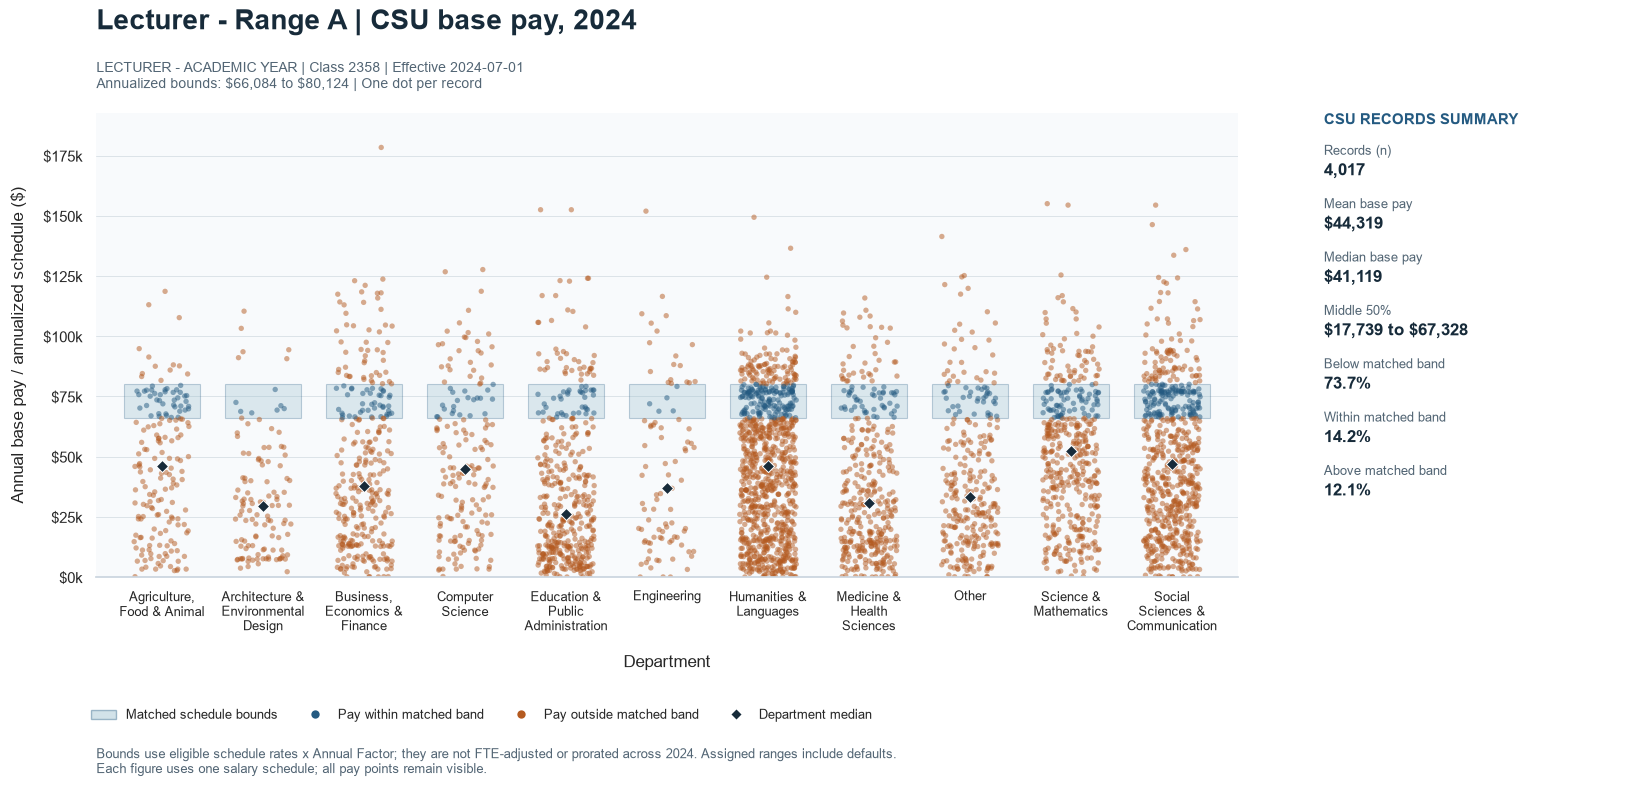

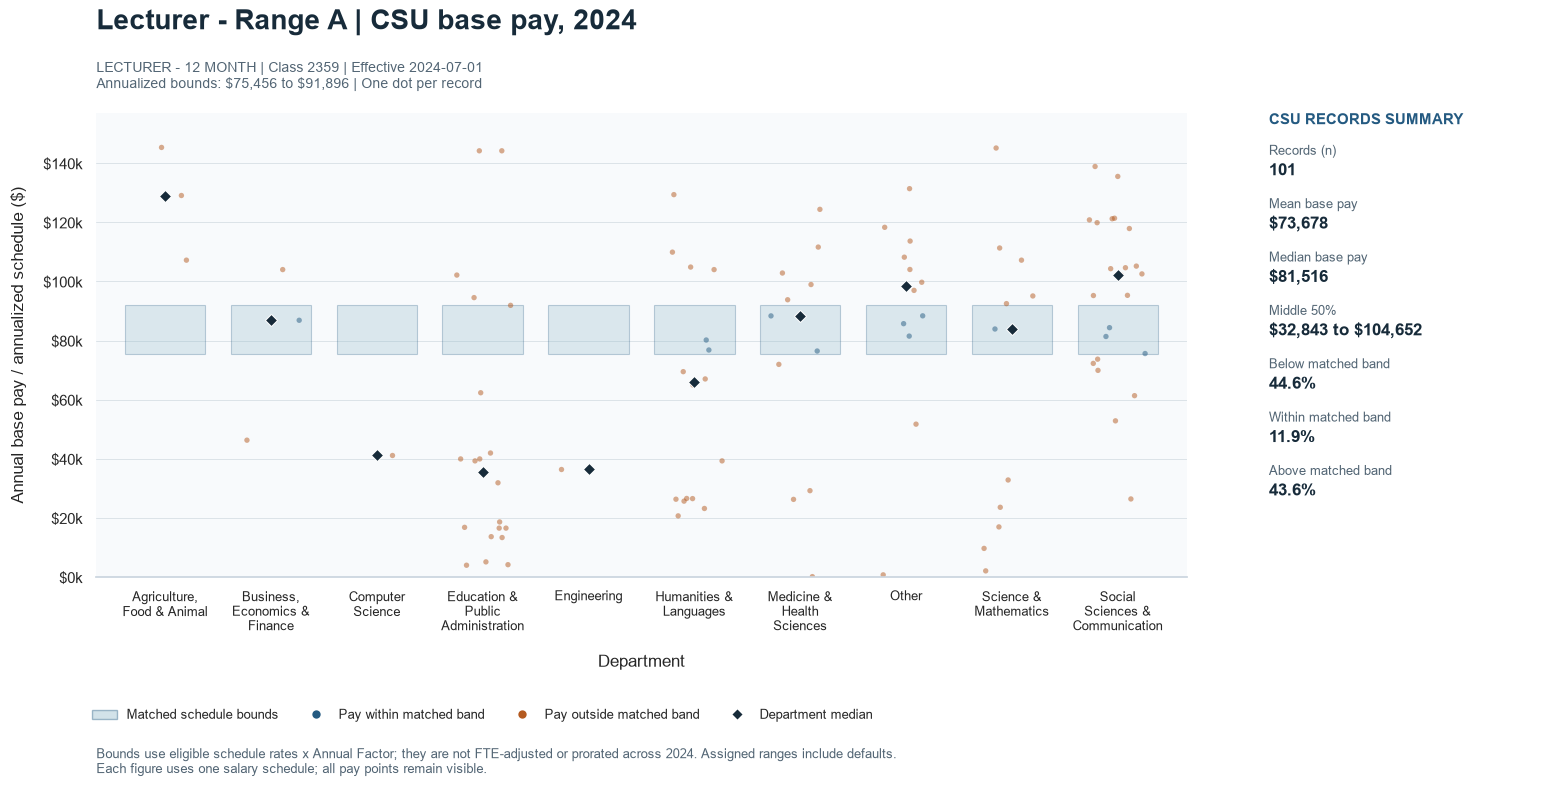

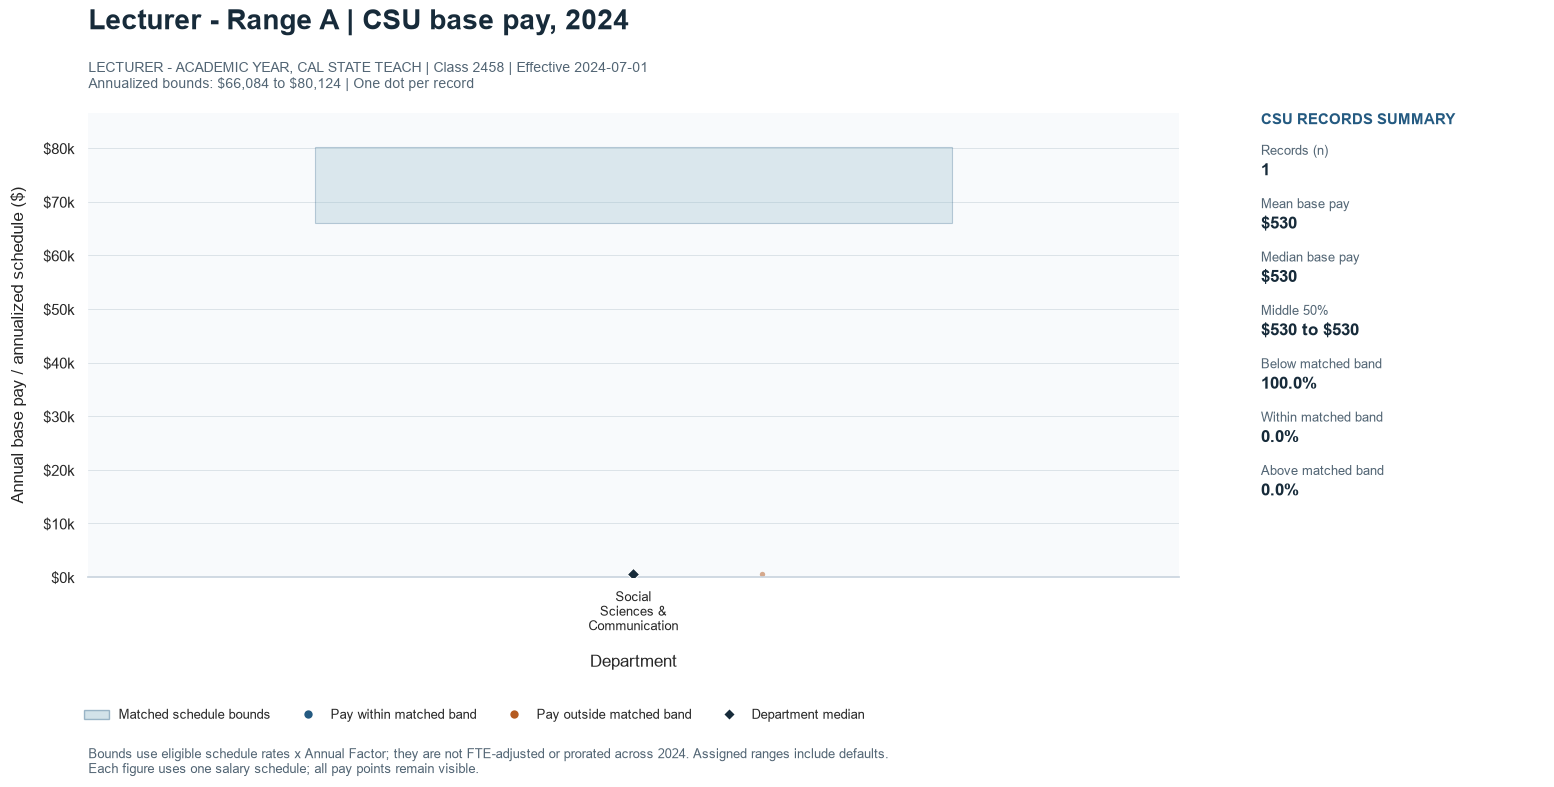

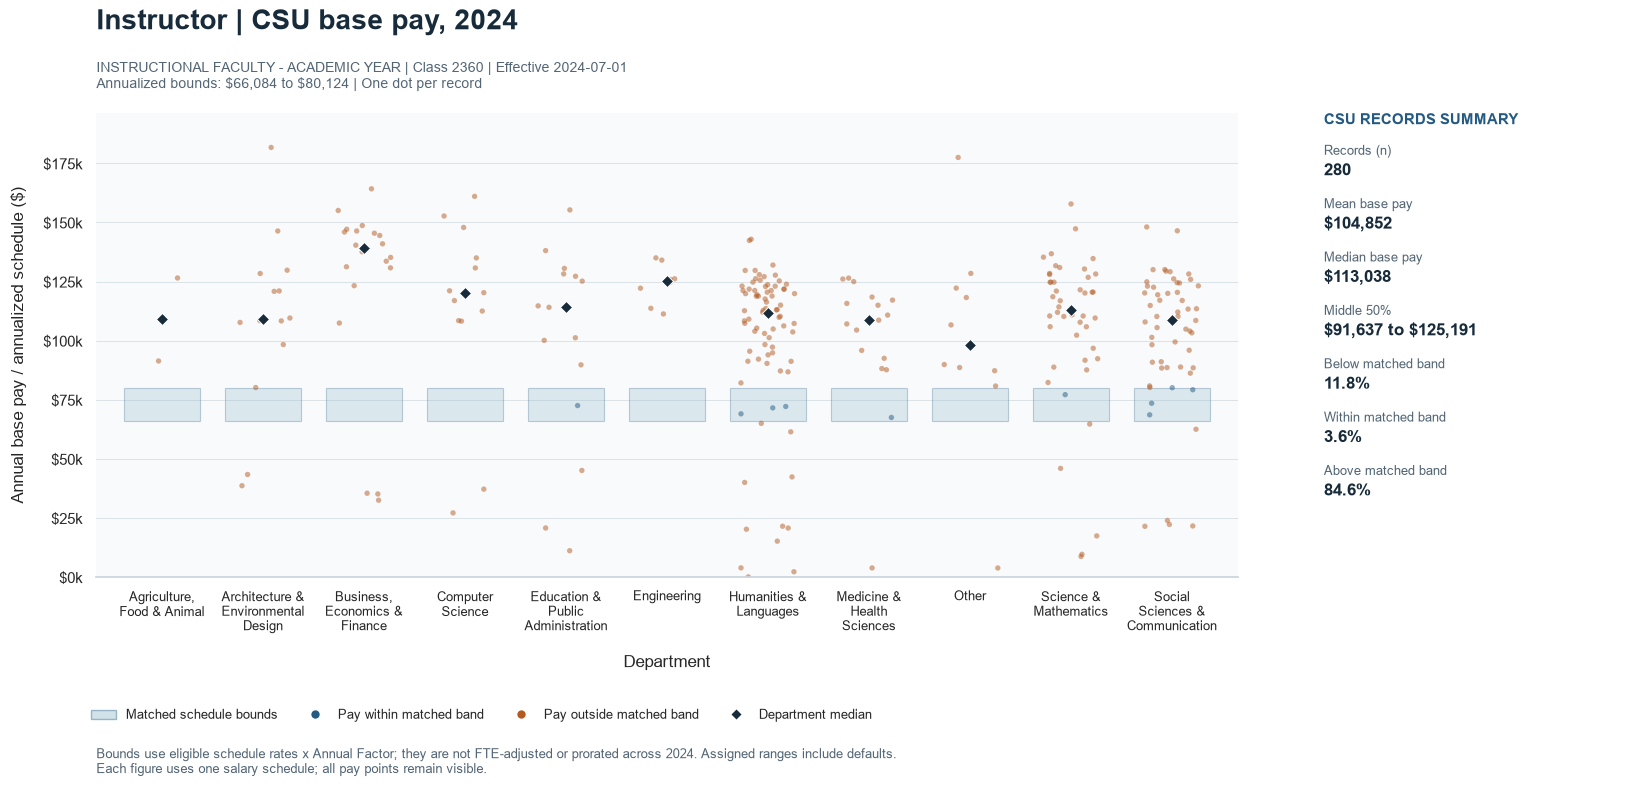

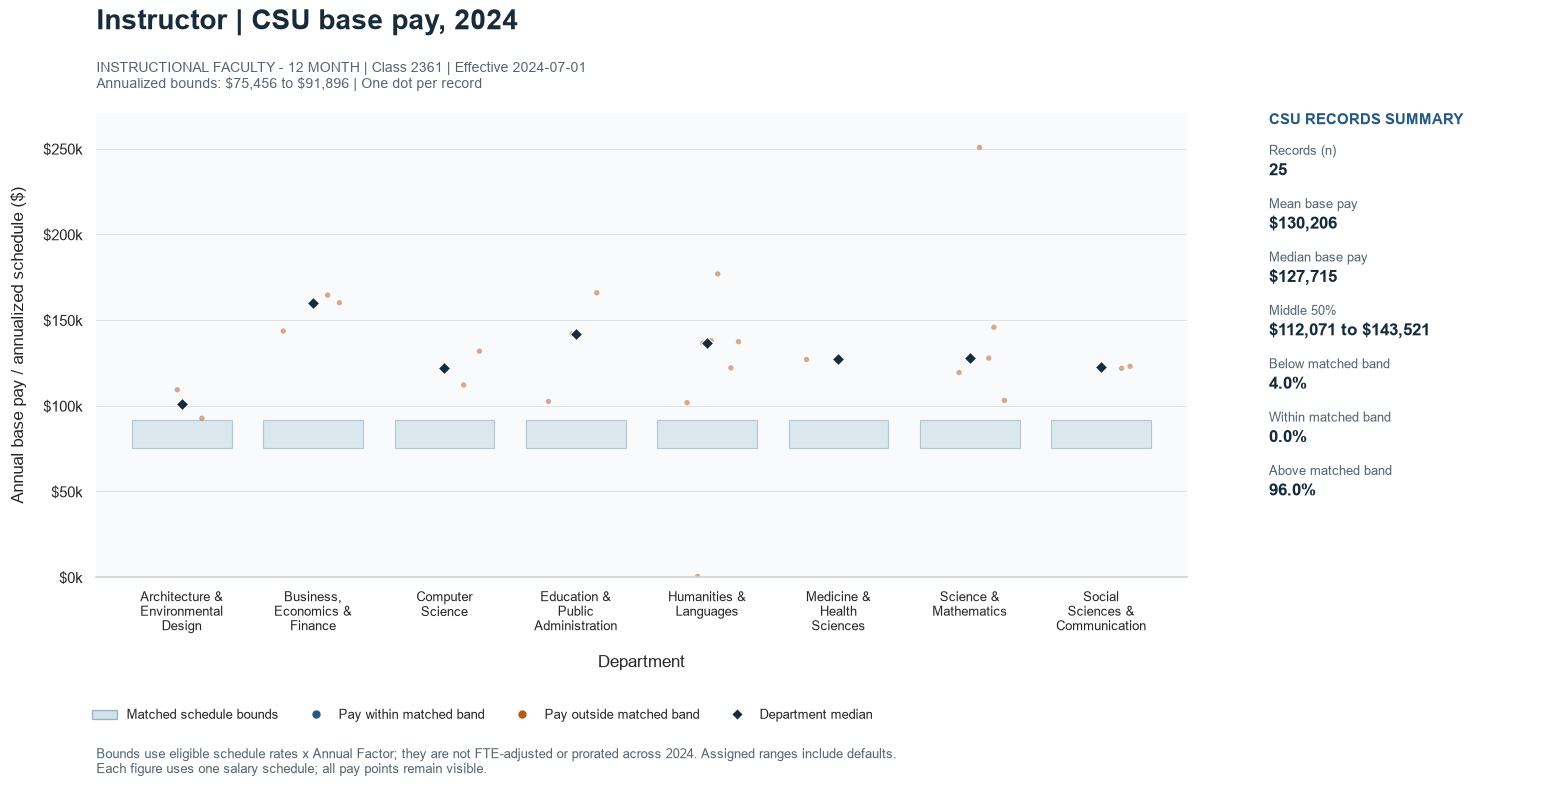

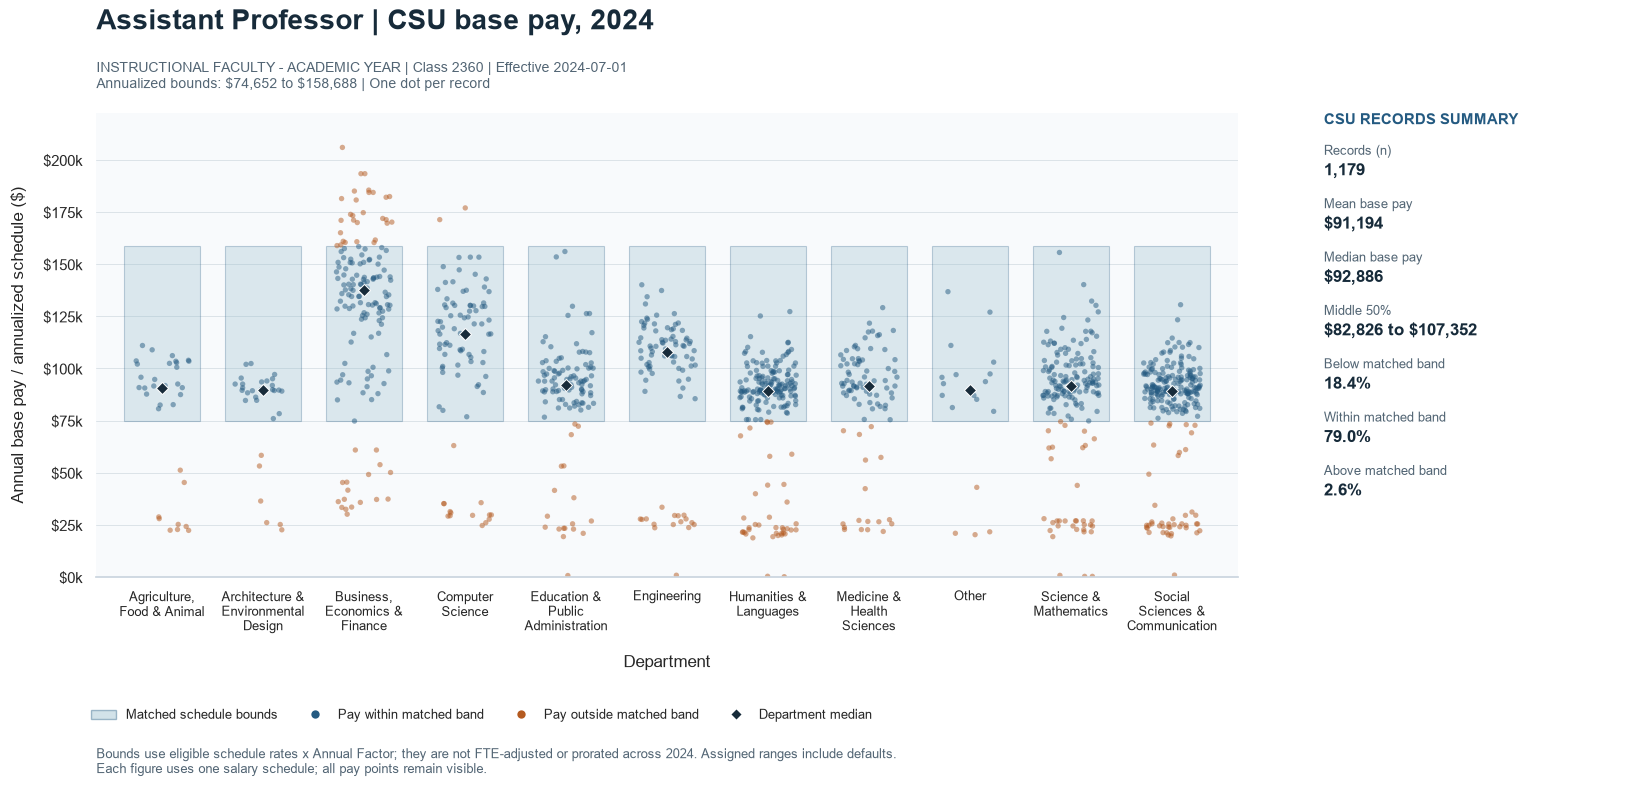

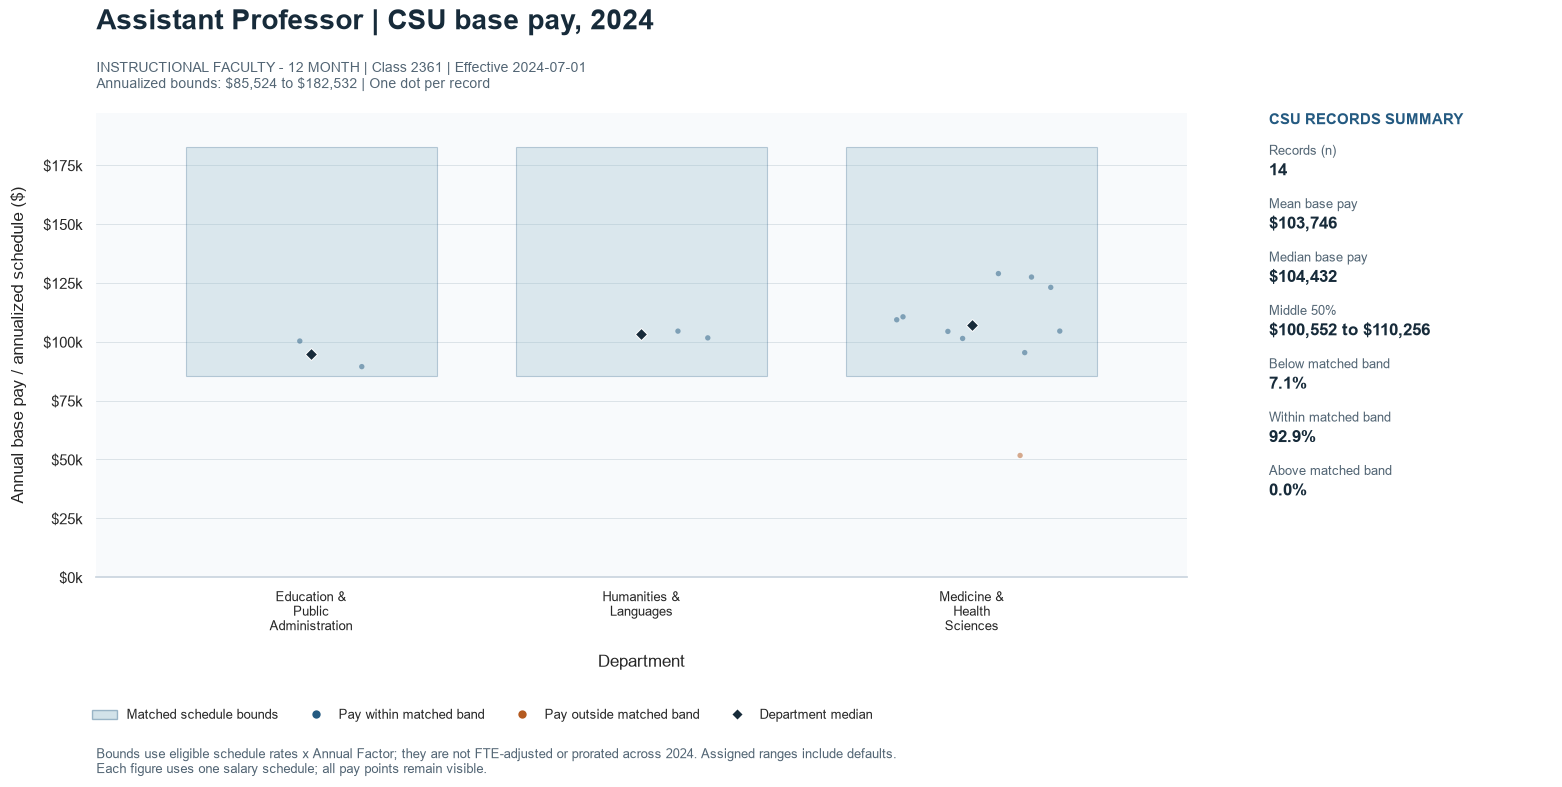

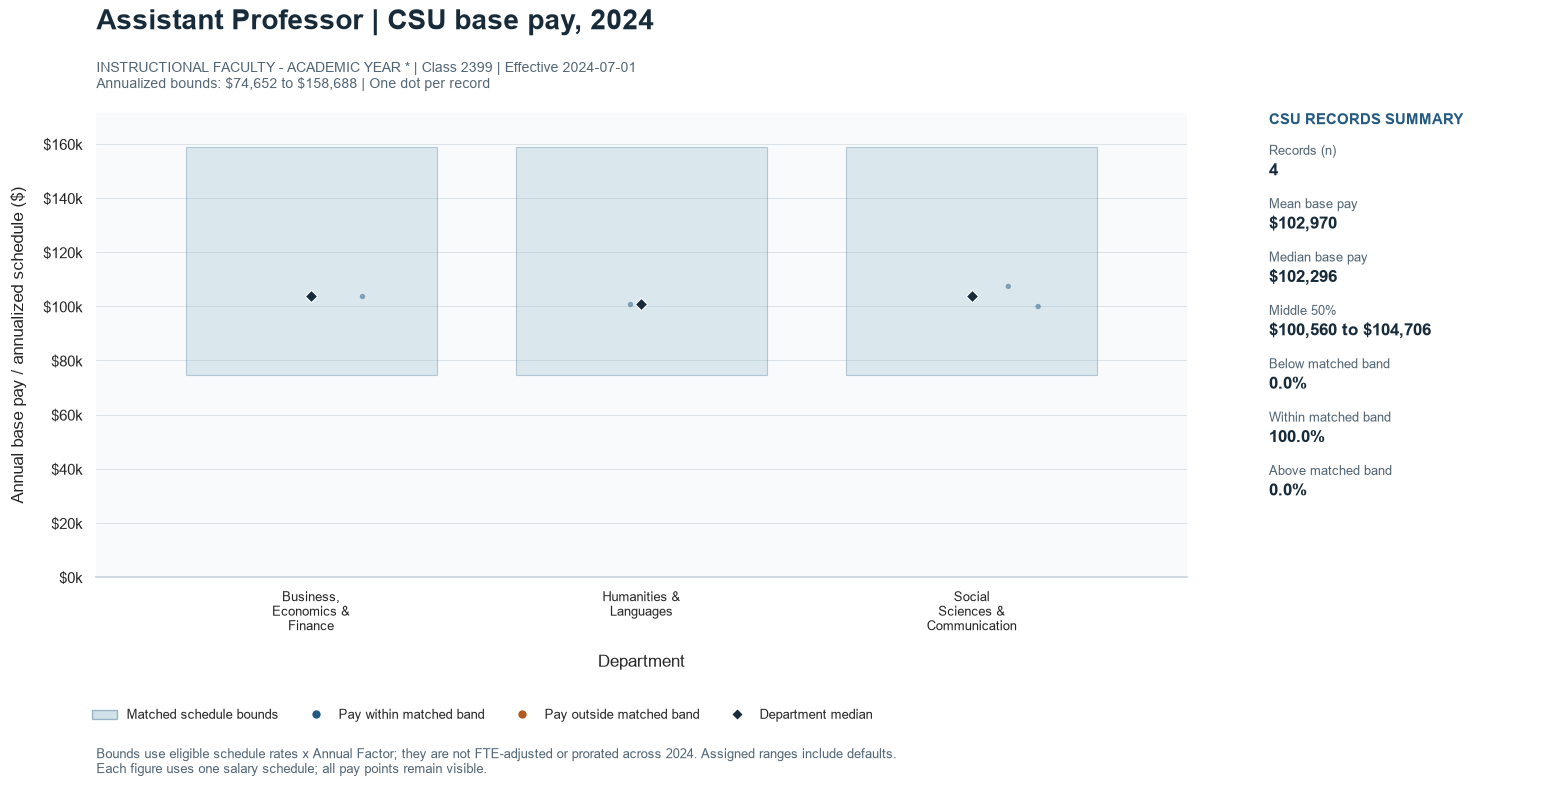

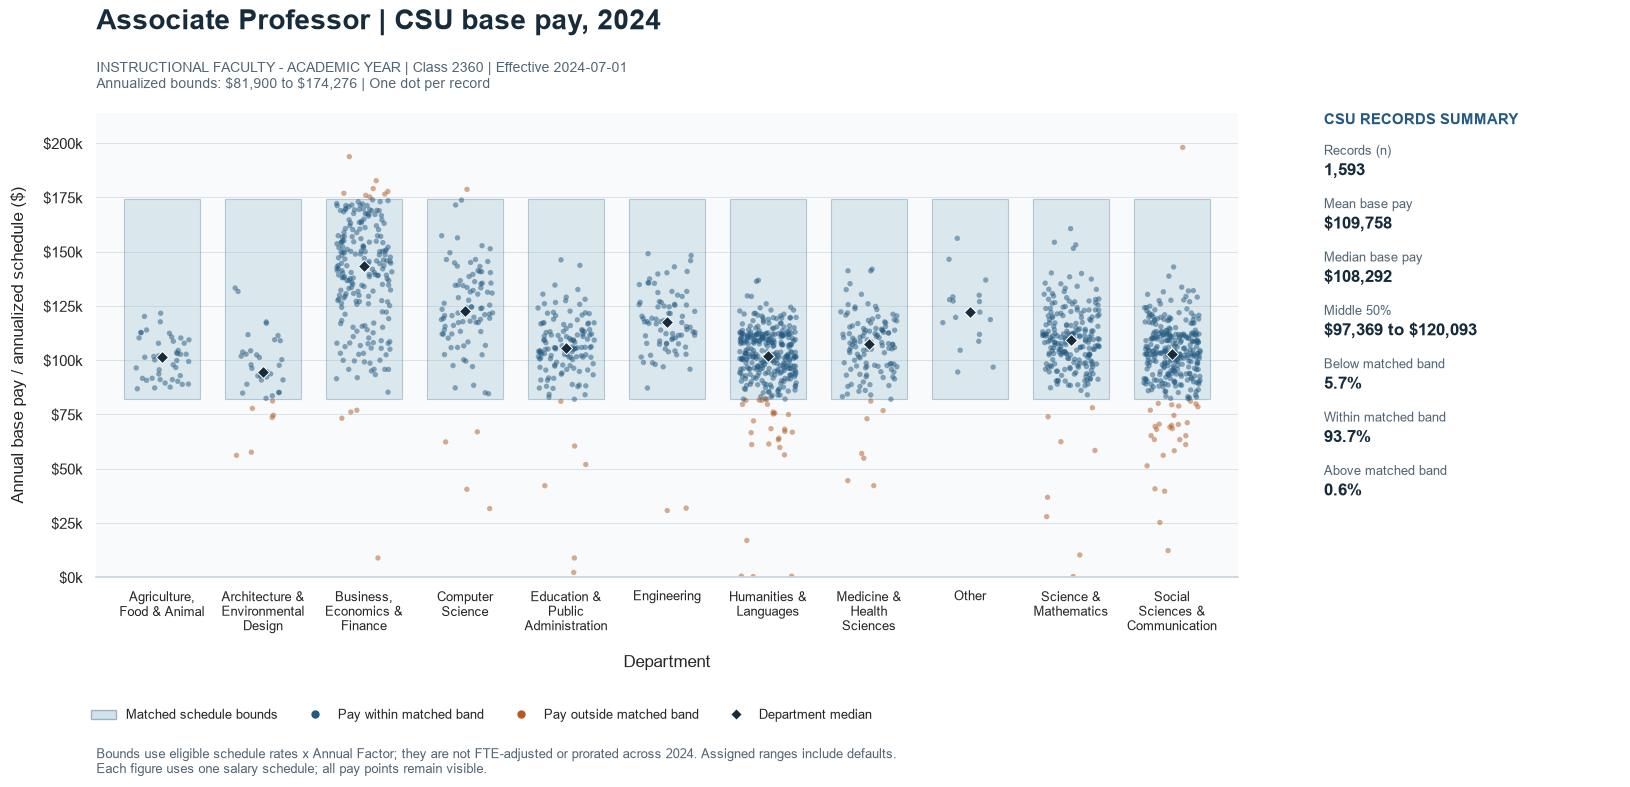

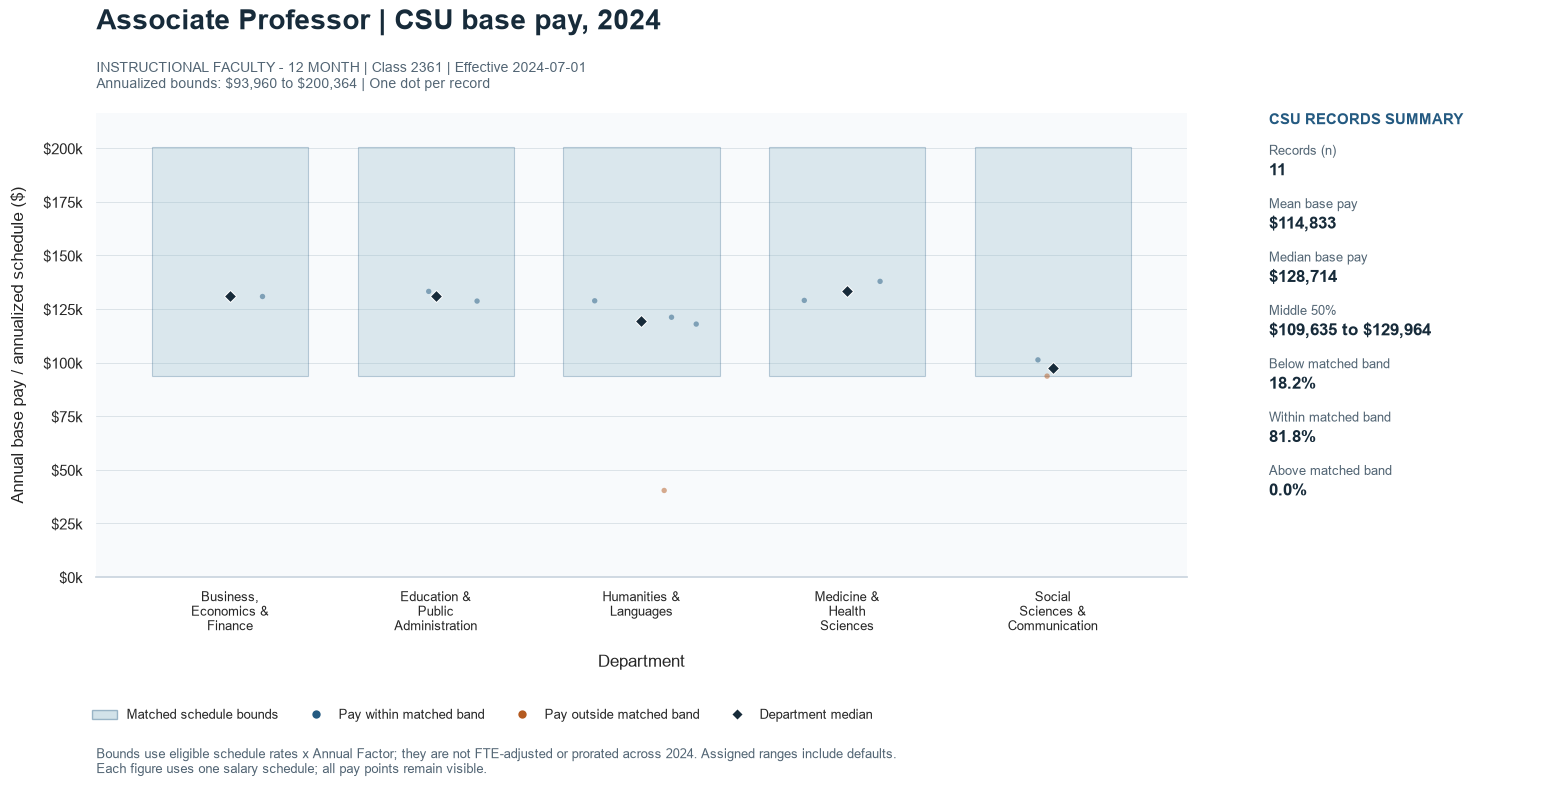

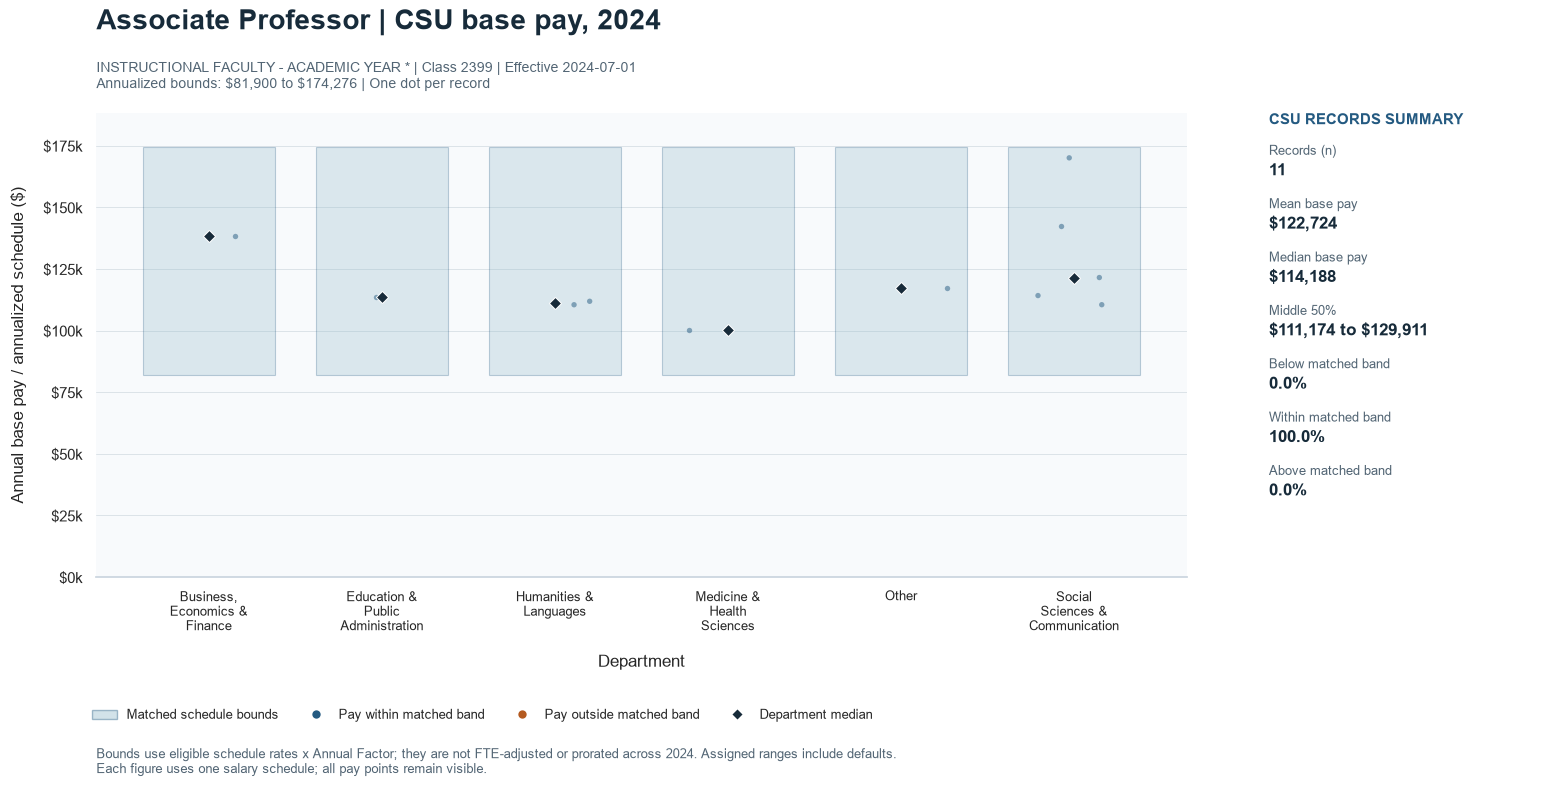

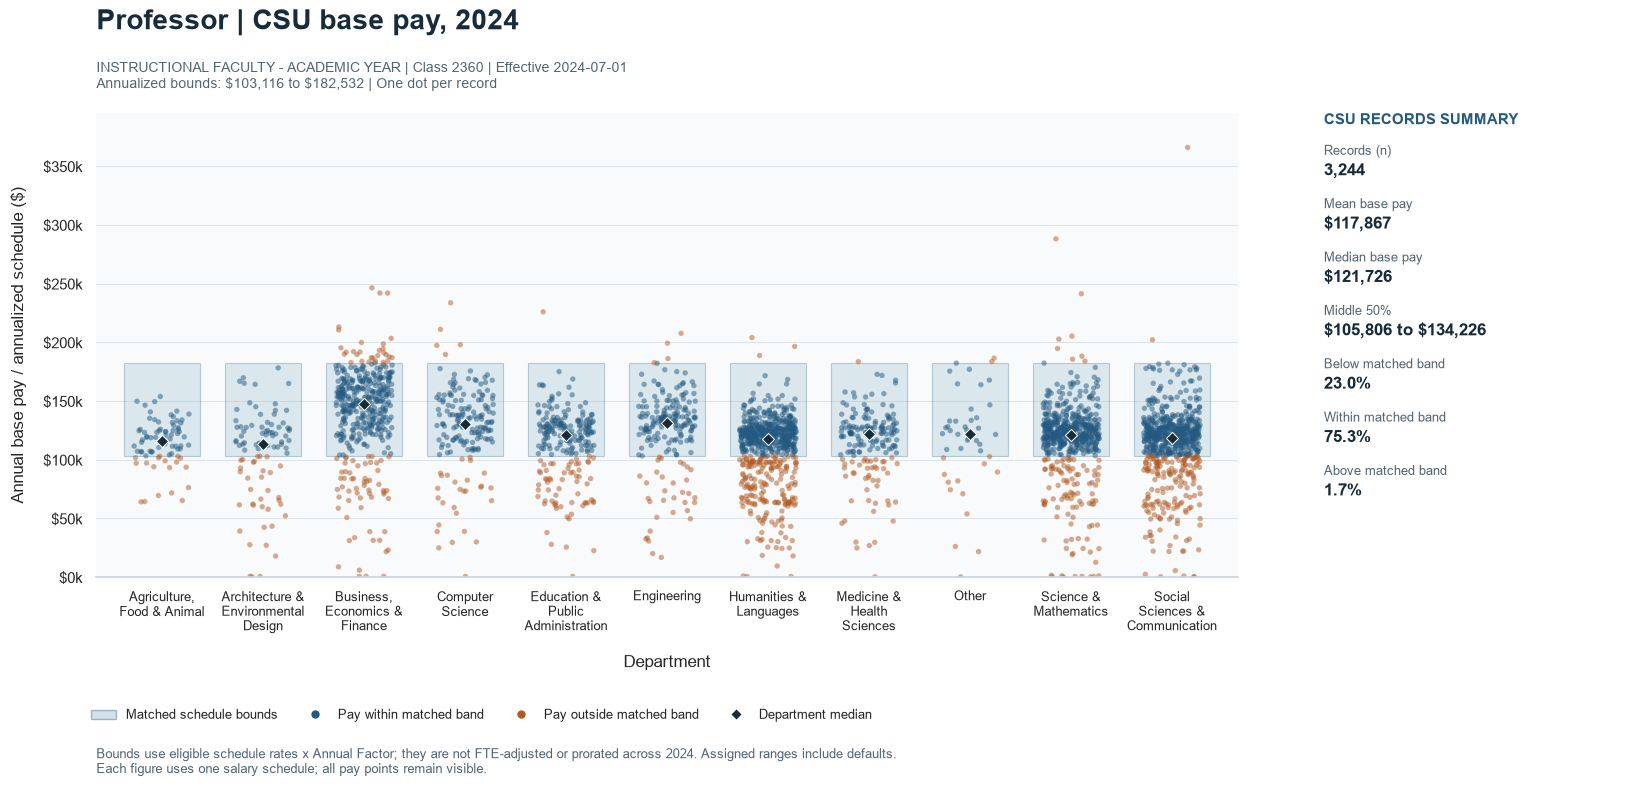

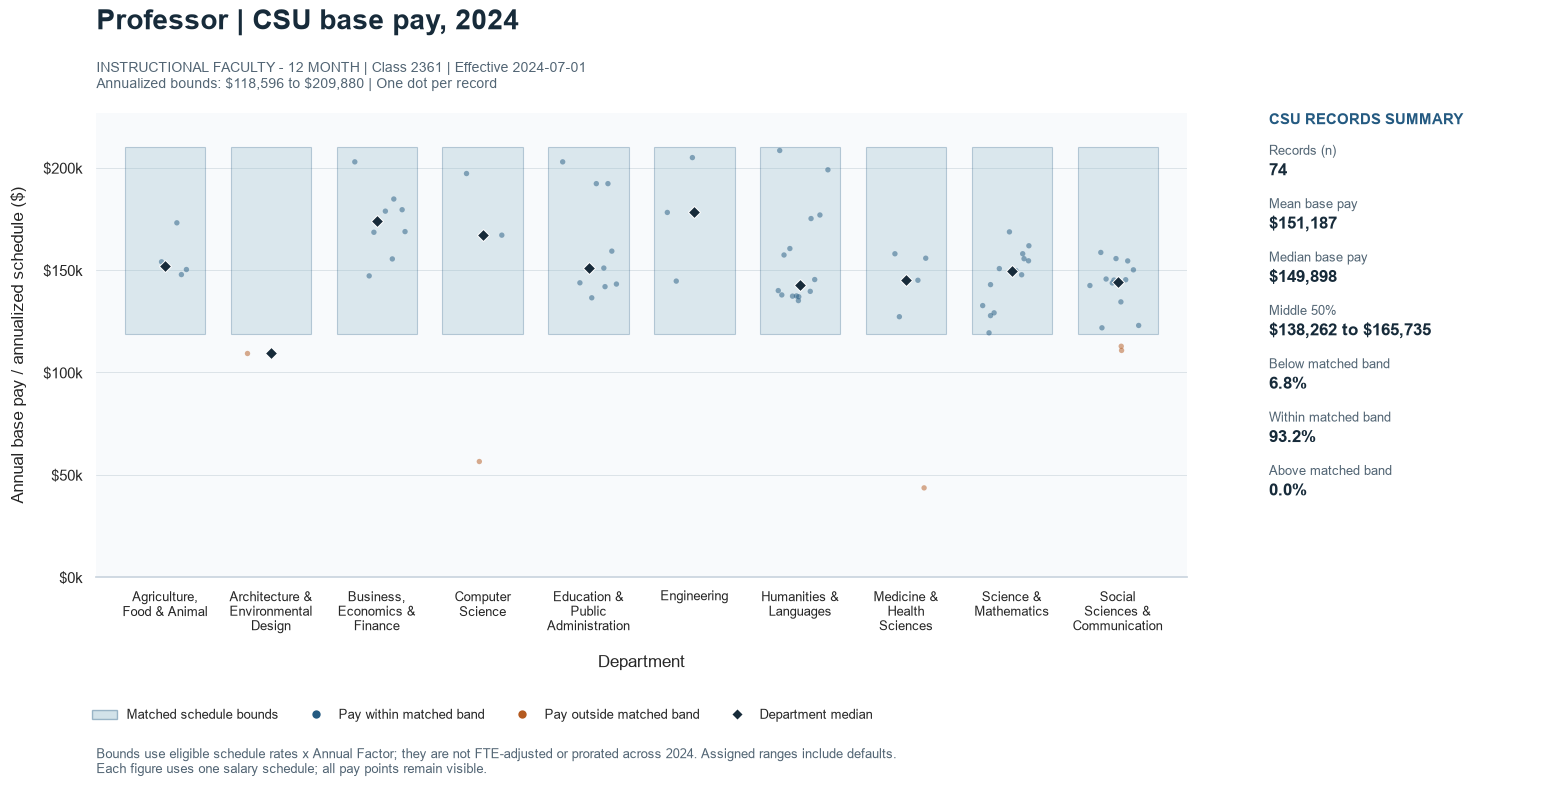

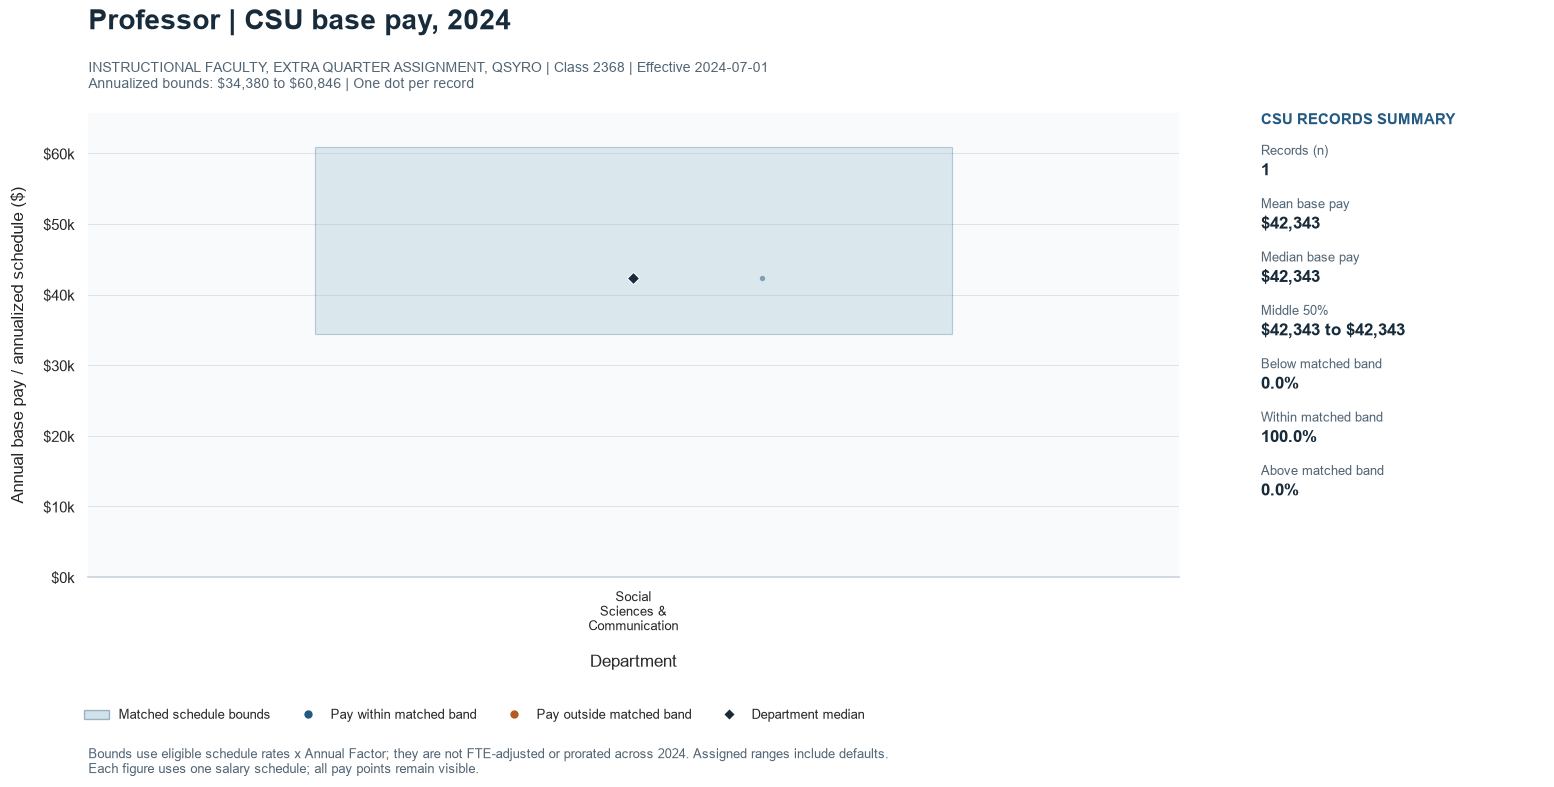

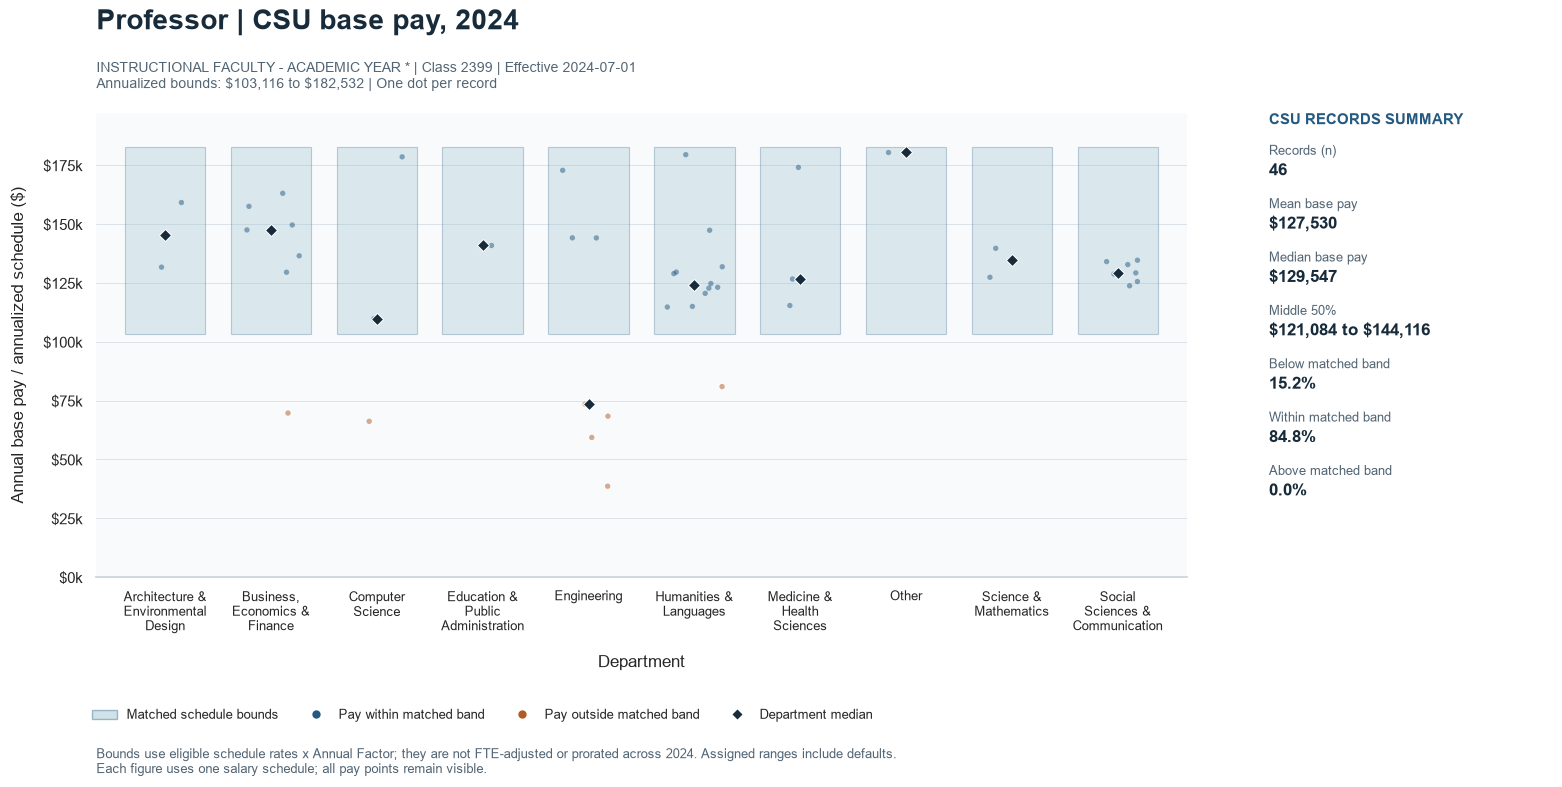

In [ ]:
def plot_salary_range(range_title, group):
    departments = sorted(group["department"].unique())
    schedule = group.iloc[0]
    assert group[["salary_low", "salary_high"]].drop_duplicates().shape[0] == 1
    low, high = schedule["salary_low"], schedule["salary_high"]
    rng = np.random.default_rng(42)
    fig, (ax, side) = plt.subplots(
        1, 2, figsize=(max(16, len(departments) * 1.25 + 3), 8),
        gridspec_kw={"width_ratios": [5, 1.3]},
    )
    fig.patch.set_facecolor("white")
    ax.set_facecolor("#f8fafc")
    blue, orange, band = "#245a81", "#b45a20", "#8fb8c9"

    for position, department in enumerate(departments):
        rows = group.loc[group["department"].eq(department)]
        ax.add_patch(Rectangle(
            (position - 0.38, low), 0.76, high - low,
            facecolor=band, edgecolor=blue, linewidth=0.8, alpha=0.28, zorder=1,
        ))
        x = position + rng.uniform(-0.28, 0.28, len(rows))
        outside = rows["below_range"] | rows["above_range"]
        ax.scatter(x, rows["base_pay"], s=15, alpha=0.5,
                   c=np.where(outside, orange, blue), linewidths=0, zorder=2)
        ax.scatter(position, rows["base_pay"].median(), marker="D", s=38,
                   color="#172b3a", edgecolors="white", linewidths=0.7, zorder=4)

    name = "Lecturer - Range A" if range_title == "A" else range_title.title()
    fig.suptitle(f"{name} | CSU base pay, 2024", x=0.07, ha="left",
                 fontsize=20, fontweight="bold", color="#172b3a")
    effective = pd.Timestamp(schedule["Effective Date"]).strftime("%Y-%m-%d")
    subtitle = (f"{schedule['Class Title']} | Class {int(schedule['Class'])} | Effective {effective}"
                f"\nAnnualized bounds: ${low:,.0f} to ${high:,.0f} | One dot per record")
    ax.set_title(subtitle,
                 loc="left", fontsize=10, color="#526574", pad=18, parse_math=False)
    ax.set_xticks(range(len(departments)))
    ax.set_xticklabels([fill(str(d), 14) for d in departments], fontsize=9)
    ax.set_xlabel("Department", labelpad=15)
    ax.set_ylabel("Annual base pay / annualized schedule ($)", labelpad=12)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"${value / 1000:,.0f}k"))
    ax.set_xlim(-0.65, len(departments) - 0.35)
    ax.set_ylim(0, max(group["base_pay"].max(), group["salary_high"].max()) * 1.08)
    ax.grid(axis="y", color="#dce3e8", linewidth=0.7)
    ax.grid(axis="x", visible=False)
    ax.set_axisbelow(True)
    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)
    ax.spines["bottom"].set_color("#cbd5df")

    side.axis("off")
    pay = group["base_pay"]
    within = ~(group["below_range"] | group["above_range"])
    stats = [
        ("Records (n)", f"{len(group):,}"),
        ("Mean base pay", f"${pay.mean():,.0f}"),
        ("Median base pay", f"${pay.median():,.0f}"),
        ("Middle 50%", f"${pay.quantile(.25):,.0f} to ${pay.quantile(.75):,.0f}"),
        ("Below matched band", f"{group['below_range'].mean():.1%}"),
        ("Within matched band", f"{within.mean():.1%}"),
        ("Above matched band", f"{group['above_range'].mean():.1%}"),
    ]
    side.text(0, 1.0, "CSU RECORDS SUMMARY", transform=side.transAxes,
              fontsize=11, fontweight="bold", color=blue, va="top")
    for j, (label, value) in enumerate(stats):
        y = 0.91 - j * 0.115
        side.text(0, y, label, transform=side.transAxes, fontsize=9, color="#526574")
        side.text(0, y - 0.044, value, transform=side.transAxes,
                  fontsize=12, fontweight="bold", color="#172b3a", parse_math=False)

    handles = [
        Patch(facecolor=band, edgecolor=blue, alpha=.4, label="Matched schedule bounds"),
        Line2D([], [], marker="o", color="none", markerfacecolor=blue,
               markeredgecolor="none", label="Pay within matched band"),
        Line2D([], [], marker="o", color="none", markerfacecolor=orange,
               markeredgecolor="none", label="Pay outside matched band"),
        Line2D([], [], marker="D", color="none", markerfacecolor="#172b3a",
               markeredgecolor="white", label="Department median"),
    ]
    fig.legend(handles=handles, loc="lower left", bbox_to_anchor=(.06, .075),
               ncol=4, frameon=False, fontsize=9)
    fig.text(.07, .025,
             "Bounds use eligible schedule rates x Annual Factor; they are not FTE-adjusted or prorated across 2024. "
             "Assigned ranges include defaults.\nEach figure uses one salary schedule; all pay points remain visible.",
             fontsize=9, color="#526574")
    fig.subplots_adjust(left=.07, right=.98, top=.85, bottom=.27, wspace=.12)
    return fig

schedule_columns = ["Class", "Class Title", "Range", "Effective Date", "salary_low", "salary_high"]

range_order = ["A", "INSTRUCTOR", "ASSISTANT PROFESSOR", "ASSOCIATE PROFESSOR", "PROFESSOR"]
range_order += sorted(set(plot_df["Range Title"]) - set(range_order))
for range_title in range_order:
    range_rows = plot_df.loc[plot_df["Range Title"].eq(range_title)]
    for _, group in range_rows.groupby(schedule_columns, dropna=False, sort=True):
        plot_salary_range(range_title, group)
        plt.show()


In [ ]:
# Department statistics for each schedule.
department_pay_summary = (
    plot_df.groupby(["Range Title"] + schedule_columns + ["department"], dropna=False)
    .agg(n=("base_pay", "size"), mean=("base_pay", "mean"),
         median=("base_pay", "median"),
         p25=("base_pay", lambda x: x.quantile(.25)),
         p75=("base_pay", lambda x: x.quantile(.75)))
    .round(2)
)
department_pay_summary


n  \
Range Title Class  Class Title                             Range Effective Date salary_low salary_high department                                 
A           2358.0 LECTURER - ACADEMIC YEAR                2.0   2024-07-01     66084.0    80124.0     Agriculture, Food & Animal           174   
                                                                                                       Architecture & Environmental Design  116   
                                                                                                       Business, Economics & Finance        309   
                                                                                                       Computer Science                     174   
                                                                                                       Education & Public Administration    422   
...                                                                                                                                         ...   
PROFESSOR   2399.0 INSTRUCTIONAL FACULTY - ACADEMIC YEAR * 5.0   2024-07-01     103116.0   182532.0    Humanities & Languages                12   
                                                                                                       Medicine & Health Sciences             3   
                                                                                                       Other                                  1   
                                                                                                       Science & Mathematics                  3   
                                                                                                       Social Sciences & Communication        7   

                                                                                                                                                 mean  \
Range Title Class  Class Title                             Range Effective Date salary_low salary_high department                                       
A           2358.0 LECTURER - ACADEMIC YEAR                2.0   2024-07-01     66084.0    80124.0     Agriculture, Food & Animal            46115.43   
                                                                                                       Architecture & Environmental Design   33225.17   
                                                                                                       Business, Economics & Finance         45279.29   
                                                                                                       Computer Science                      47820.36   
                                                                                                       Education & Public Administration     35674.92   
...                                                                                                                                               ...   
PROFESSOR   2399.0 INSTRUCTIONAL FACULTY - ACADEMIC YEAR * 5.0   2024-07-01     103116.0   182532.0    Humanities & Languages               126573.83   
                                                                                                       Medicine & Health Sciences           138685.33   
                                                                                                       Other                                 180394.0   
                                                                                                       Science & Mathematics                133927.67   
                                                                                                       Social Sciences & Communication      129810.14   

                                                                                                                                              median  \
Range Title Class  Class Title                             Range Effective Date salary_l

In [ ]:
# Percentages use the same records and annualized bounds as the plots.
# Records without usable bounds are excluded, not counted as outside the range.
def salary_range_summary(group_column):
    totals = csu_salary_joined_df.groupby(group_column, dropna=False).size().rename("total_records")
    counts = (
        plot_df.assign(within_range=~(plot_df["below_range"] | plot_df["above_range"]))
        .groupby(group_column, dropna=False)
        .agg(
            compared_records=("base_pay", "size"),
            within_range=("within_range", "sum"),
            below_range=("below_range", "sum"),
            above_range=("above_range", "sum"),
        )
    )
    result = totals.to_frame().join(counts)
    count_columns = ["compared_records", "within_range", "below_range", "above_range"]
    result[count_columns] = result[count_columns].fillna(0).astype(int)
    result["excluded_records"] = result["total_records"] - result["compared_records"]
    denominator = result["compared_records"].replace(0, float("nan"))
    for label in ["within", "below", "above"]:
        result[f"{label}_range_pct"] = (100 * result[f"{label}_range"] / denominator).round(2)
    return result[[
        "total_records", "compared_records", "excluded_records",
        "within_range", "below_range", "above_range",
        "within_range_pct", "below_range_pct", "above_range_pct",
    ]].sort_values("within_range_pct", ascending=False, na_position="last")

school_range_summary = salary_range_summary("school")
school_range_summary


,total_records,compared_records,excluded_records,within_range,below_range,above_range,within_range_pct,below_range_pct,above_range_pct
school,,,,,,,,,
California State University San Marcos,218,216,2,180,25,11,83.33,11.57,5.09
"California State University, Sacramento",618,614,4,508,73,33,82.74,11.89,5.37
"California State University, Dominguez Hills",283,259,24,208,45,6,80.31,17.37,2.32
Cal Poly San Luis Obispo,596,594,2,473,113,8,79.63,19.02,1.35
"California State University, Fullerton",784,783,1,609,86,88,77.78,10.98,11.24
San Francisco State University,555,537,18,411,96,30,76.54,17.88,5.59
CSU Northridge,480,472,8,300,161,11,63.56,34.11,2.33
"California State University, East Bay",181,181,0,102,69,10,56.35,38.12,5.52
San Diego State University,1159,1140,19,637,413,90,55.88,36.23,7.89


In [ ]:
# Salary range comparison by department bucket.
department_range_summary = salary_range_summary("department")
department_range_summary


,total_records,compared_records,excluded_records,within_range,below_range,above_range,within_range_pct,below_range_pct,above_range_pct
department,,,,,,,,,
Engineering,502,462,40,310,122,30,67.10,26.41,6.49
"Business, Economics & Finance",1165,1130,35,689,304,137,60.97,26.90,12.12
Science & Mathematics,1510,1469,41,882,465,122,60.04,31.65,8.30
Computer Science,565,542,23,317,175,50,58.49,32.29,9.23
Social Sciences & Communication,2083,1995,88,1125,717,153,56.39,35.94,7.67
"Agriculture, Food & Animal",344,337,7,171,148,18,50.74,43.92,5.34
Humanities & Languages,2296,2228,68,1093,948,187,49.06,42.55,8.39
Medicine & Health Sciences,824,807,17,375,373,59,46.47,46.22,7.31
Education & Public Administration,975,935,40,424,449,62,45.35,48.02,6.63


In [ ]:
# Most common assigned ranges, as a percentage of all 2024 CSU records.
range_labels = (
    csu_salary_joined_df["Range Title"].astype("string").str.strip()
    .replace("", pd.NA).fillna("(Matched: blank Range Title)")
    .where(csu_salary_joined_df["salary_match"].eq("both"), "(Unmatched)")
)
top_range_title_summary = (
    range_labels.value_counts().rename_axis("Range Title")
    .reset_index(name="csu_records")
)
top_range_title_summary["percent_of_csu_records"] = (
    100 * top_range_title_summary["csu_records"] / max(len(csu_salary_joined_df), 1)
).round(2)
top_range_title_summary.head(10)


,Range Title,csu_records,percent_of_csu_records
0,A,4119,37.24
1,PROFESSOR,3365,30.42
2,ASSOCIATE PROFESSOR,1615,14.6
3,ASSISTANT PROFESSOR,1197,10.82
4,(Unmatched),375,3.39
5,INSTRUCTOR,305,2.76
6,(Matched: blank Range Title),84,0.76
